# EDA 11: gap-stay và chọn max gap

Tiếp nối `10_stay_anchor.ipynb`. Gap-stay là phần giờ stay đến từ khoảng trống > 30 phút (máy tắt hoặc mất tín hiệu): thuật toán coi người dùng ở yên nếu hai phía khoảng trống đều nằm trong bán kính stay (giả định A12). `MAX_GAP_S` trong `detect.py` đang là 24 giờ (mặc định tạm, chưa chọn). Notebook này chọn **max gap**: khoảng trống dài hơn mức nào thì ngắt dữ liệu, không nối thành stay.

| Mục | Câu hỏi |
|---|---|
| 1 | Gap-stay chiếm bao nhiêu giờ stay, và khi hai đầu khoảng trống xa nhau thì người dùng đang làm gì? |
| 2 | Max gap: khoảng trống dài cỡ nào thì hai đầu còn gần nhau (2.1), cắt ở mỗi mức thì mất bao nhiêu giờ và bằng chứng đêm, so với 72 giờ (2.2), khoảng trống trên 24 giờ so với home / office từ GPS (2.3), độ nhạy khi đổi từng cặp mức (2.4). **Không có đáp án home / office nên không chứng minh được mức đúng; mức max gap sẽ là quy ước (D16), chưa chọn.** |

**Cách chạy.** Cần `data/processed/clean`. Kết quả từng user lưu ở `data/interim/eda_stay_anchor_mean/` (dùng chung với notebook 10); đổi code `src/eda/stay_anchor.py` thì xoá thư mục này. Mục 1 chạy 1–2 phút, mục 2.1 vài phút, mục 2.2 tính nặng ở lần đầu (chạy `h1_mean` lại cho từng mức max gap, vài chục phút cho nhóm validation), sau đó đọc cache `<user>_maxgap.pkl`.

> **Giai đoạn: TUNING (sau khi chia validation / test).** Chỉ đọc **nhóm validation** (`split.val_users()`). Không dùng nhóm test (D17, D19).
>
> Các số trong ô văn bản bên dưới là của lần chạy cũ (bản chia 06/11); cập nhật sau khi chạy lại.

In [1]:
# chạy được ngay cả khi chưa chạy các mục trước
import importlib
from pathlib import Path
import sys
import numpy as np
import pandas as pd
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir())
if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))
from preprocess import interim
from eda import stay_anchor as sa
from eda import stay_anchor_plots as sp
from eda import split
importlib.reload(sa); importlib.reload(sp)

<module 'eda.stay_anchor_plots' from 'C:\\Users\\Acer\\OneDrive\\Desktop\\Home_Office\\src\\eda\\stay_anchor_plots.py'>

## 1. Gap-stay: giờ của chúng nhiều đến đâu, hai đầu xa nhau là gì

Li đo khoảng cách tới **neo**, nên hai đầu một khoảng trống có thể cách **nhau** tới 2D = 400 m. Bảng dưới cho tổng giờ stay, phần giờ nằm trong khoảng trống (`gap_hours`) và phần giờ của gap-stay có hai đầu cách nhau > 200 m (`far_gap_hours`).

In [2]:
GAP_USERS = None      # ví dụ ["000", "001", "002"] để chạy thử nhanh

gap_users = split.val_users()
if GAP_USERS:
    gap_users = [u for u in gap_users if u in set(GAP_USERS)]
S22, _ = sa.run_users(gap_users, sa.VARIANTS)       # dùng chung kết quả đã lưu của notebook 10

bang22 = S22.groupby("variant")[["n_stays", "hours", "gps_hours", "gap_hours", "far_gap_hours"]].sum().reindex(sa.VARIANTS)
bang22["% giờ là gap"] = 100 * bang22["gap_hours"] / bang22["hours"]
bang22["% giờ far_gap"] = 100 * bang22["far_gap_hours"] / bang22["hours"]
print(f"Bảng 1. {S22['user'].nunique()} user")
display(bang22.round(1))

115 user đã có kết quả, 0 user cần tính, 15 tiến trình
Bảng 1. 115 user


,n_stays,hours,gps_hours,gap_hours,far_gap_hours,% giờ là gap,% giờ far_gap
variant,,,,,,,
li,11444,54646.9,5380.5,49266.4,10739.8,90.2,19.7
h1_mean,10829,55291.7,5764.0,49527.7,10864.1,89.6,19.6


### 1.1 Hai đầu xa nhau là gì?

Kiểm tra giả định "tắt máy ở một chỗ, bật lại ở chỗ khác" cho các gap-stay có hai đầu cách nhau > 200 m. **Lúc tắt và lúc bật máy, người dùng có đang di chuyển không?** Tốc độ của 6 điểm ngay trước và sau khoảng trống; > 3 km/h là đang đi. Nếu đang đi thì hai đầu là điểm trên đường đi tới và rời khỏi nơi ở lại, không phải vị trí ở yên.

Chạy song song, khoảng 1–2 phút cho nhóm validation.

In [3]:
E23 = sa.run_far_gap_ends(split.val_users())
E23["đang đi lúc tắt"] = E23["kmh_before"] > 3
E23["đang đi lúc bật"] = E23["kmh_after"] > 3
print(f"{len(E23)} gap-stay có hai đầu cách nhau > 200 m, {E23['dur_h'].sum():,.0f} giờ, {E23['user'].nunique()} user")
tom = pd.Series({
    "% giờ là khoảng trống qua đêm (tắt 18–3h, bật 5–12h)": 100 * (E23["dur_h"] * E23["overnight"]).sum() / E23["dur_h"].sum(),
    "% đang đi lúc tắt máy": 100 * E23["đang đi lúc tắt"].mean(),
    "% đang đi lúc bật máy": 100 * E23["đang đi lúc bật"].mean(),
    "% đứng yên cả lúc tắt lẫn lúc bật": 100 * (~E23["đang đi lúc tắt"] & ~E23["đang đi lúc bật"]).mean(),
    "trung vị khoảng cách hai đầu (m)": E23["end_m"].median(),
    "trung vị độ dài khoảng trống (giờ)": E23["gap_h"].median(),
})
display(tom.round(1).to_frame("giá trị"))

1178 gap-stay có hai đầu cách nhau > 200 m, 10,740 giờ, 78 user


,giá trị
"% giờ là khoảng trống qua đêm (tắt 18–3h, bật 5–12h)",41.3
% đang đi lúc tắt máy,68.6
% đang đi lúc bật máy,85.7
% đứng yên cả lúc tắt lẫn lúc bật,4.5
trung vị khoảng cách hai đầu (m),253.7
trung vị độ dài khoảng trống (giờ),10.2


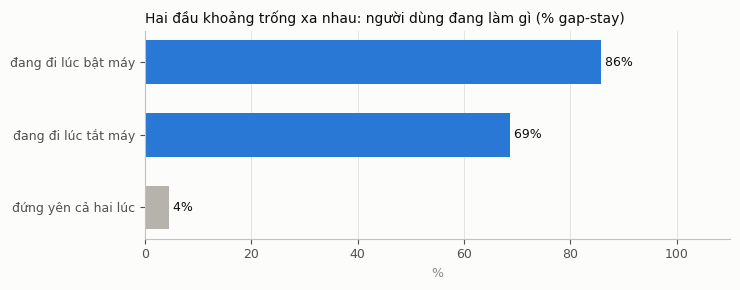

In [4]:
sp.far_gap_summary(100 * E23["đang đi lúc tắt"].mean(), 100 * E23["đang đi lúc bật"].mean(),
                   100 * (~E23["đang đi lúc tắt"] & ~E23["đang đi lúc bật"]).mean());

**Đọc kết quả** (số ở bảng và hình trên): nếu phần lớn gap-stay hai đầu xa nhau là **đang di chuyển lúc tắt và lúc bật máy**, thì hai đầu là điểm trên đường đi tới và rời khỏi nơi ở lại, không phải ở hai nơi khác nhau.

**Kết quả:** _chưa có. Chạy lại notebook trên nhóm validation của bản chia mới rồi ghi kết luận ở đây._


## 2. Chọn max gap

Mục 1 giữ gap-stay như Li. Mục này xét **max gap** (khoảng trống dài hơn mức này thì ngắt dữ liệu, hai bên chạy stay point riêng). Điểm GPS ở hai bên vẫn còn; nhưng thời gian của khoảng trống không thuộc stay nào, và đoạn ghi ngắn hơn T sau khoảng trống không thành stay. Không có đáp án home / office (A13), nên các mục dưới đo **độ nhạy và chi phí** của từng mức, không đo đúng sai.

### 2.1 Khoảng trống dài cỡ nào thì hai đầu còn gần nhau

**Tỉ lệ quay lại trên khoảng trống thật.** Với mọi khoảng trống 30 phút–72 giờ: hai điểm hai đầu có cách nhau ≤ 200 m không (gọi là "gần"), theo độ dài khoảng trống và theo qua đêm / ban ngày. Chưa biết người đó có ở yên thật không, chỉ biết hai đầu có gần nhau.

In [5]:
users23 = split.val_users()
R23 = sa._run_each(sa.real_gap_returns, users23, sa.CLEAN_DIR, None)

R23["độ dài (giờ)"] = pd.cut(R23["gap_h"], sa.LEN_BINS_H)
a = R23.groupby("độ dài (giờ)", observed=True).agg(số_khoảng_trống=("end_m", "size"), gần=("end_m", lambda x: 100 * (x <= 200).mean()))
b = R23.groupby(["độ dài (giờ)", "overnight"], observed=True)["end_m"].apply(lambda x: 100 * (x <= 200).mean()).unstack()
a["gần, ban ngày (%)"] = b[False]
a["gần, qua đêm (%)"] = b.get(True)
a = a.rename(columns={"gần": "gần, tất cả (%)"})
print("Bảng 2.1. % khoảng trống thật có hai đầu cách nhau ≤ 200 m")
display(a.round(1))

Bảng 2.1. % khoảng trống thật có hai đầu cách nhau ≤ 200 m


,số_khoảng_trống,"gần, tất cả (%)","gần, ban ngày (%)","gần, qua đêm (%)"
độ dài (giờ),,,,
"(0.5, 1.0]",3038,62.2,62.2,NaN
"(1.0, 2.0]",2331,62.3,62.3,NaN
"(2.0, 4.0]",2053,47.3,47.7,20.7
"(4.0, 8.0]",1461,37.0,34.8,55.2
"(8.0, 12.0]",3303,40.2,38.2,42.6
"(12.0, 24.0]",3813,28.5,26.8,31.9
"(24.0, 36.0]",566,20.3,16.4,33.3
"(36.0, 48.0]",429,22.8,22.3,24.7
"(48.0, 72.0]",317,17.0,15.9,19.8


**Đọc kết quả** (số ở bảng trên): nếu tỉ lệ giảm đều theo độ dài thì không có điểm gãy chỉ ra một độ dài cắt cụ thể; nếu có bước tụt rõ ở một độ dài thì đó là gợi ý cắt. Bảng chỉ nói về độ tin của **từng** khoảng trống, không nói cắt ở mức nào thì mất bao nhiêu bằng chứng home / office (việc đó ở 2.2).

**Kết quả:** _chưa có. Chạy lại notebook trên nhóm validation của bản chia mới rồi ghi kết luận ở đây._


### 2.2 Cắt ở từng mức max gap thì mất gì

Chạy `h1_mean` với max gap = 4, 8, 12, 16, 20, 24, 36, 48, 72 giờ. Chuẩn so sánh là **72 giờ**, mức dài nhất khảo sát, gần như không giới hạn (24 giờ chỉ là mặc định tạm của pipeline, được đo như mọi mức khác). Giờ còn lại luôn ≤ 100%. Với mỗi mức, so với 72 giờ:
- **giờ stay, giờ đêm (0–6h), giờ hành chính (thứ 2–6, 9–17h) còn lại** (đêm và hành chính tính theo từng user, rồi lấy trung vị và p10);
- **địa điểm đổi nơi:** địa điểm 1 lệch > 100 m; home (địa điểm nhiều giờ đêm nhất trong ba địa điểm đầu) và office (nhiều giờ hành chính nhất) khác nơi > 200 m hoặc mất hẳn bằng chứng;
- **stay bị tách / 100 stay** (một lần ở bị cắt đôi);
- **user mất bằng chứng đêm:** từ ≥ `MIN_NIGHT_H` giờ đêm xuống dưới mức đó.

Gap-stay dài hơn max gap có đáng tin hay không **không** đo được ở đây (xem 2.1, 2.3). Mục này chỉ đo cái giá của việc cắt và mức nhạy so với 72 giờ, không đo mức nào đúng.

79 user đã có kết quả, 36 user cần tính, 15 tiến trình
[10/36] (19 giây)
[20/36] (22 giây)
[30/36] (27 giây)
[36/36] (55 giây)
Bảng 2. Cắt ở từng mức max gap, so với 72 giờ (115 user)


max gap (giờ),4,8,12,16,20,24,36,48,72
số stay,7367.0,7883.0,9457.0,10501.0,10728.0,10829.0,10956.0,11070.0,11132.0
giờ stay còn lại (%),17.3,22.8,47.8,69.6,76.0,79.9,86.4,93.8,100.0
giờ gap còn lại (%),10.6,16.4,43.4,67.0,73.9,78.1,85.1,93.3,100.0
"giờ đêm còn lại, trung vị user (%)",4.1,10.0,47.0,66.9,71.4,76.6,92.3,100.0,100.0
"giờ đêm còn lại, p10 user (%)",0.0,0.0,0.0,18.1,23.4,36.3,50.1,70.8,100.0
"giờ hành chính còn lại, trung vị user (%)",18.2,25.3,65.9,79.4,82.1,89.0,98.9,100.0,100.0
"giờ hành chính còn lại, p10 user (%)",0.0,0.0,3.8,21.0,21.0,21.0,32.5,72.3,100.0
stay tách / 100 stay,6.7,6.7,5.8,5.4,5.4,5.3,5.3,5.3,5.3
user mất bằng chứng đêm,59.0,46.0,22.0,14.0,12.0,11.0,8.0,5.0,0.0
địa điểm 1 đổi nơi (% user),72.5,63.3,56.9,45.9,44.0,36.7,20.2,13.8,0.0


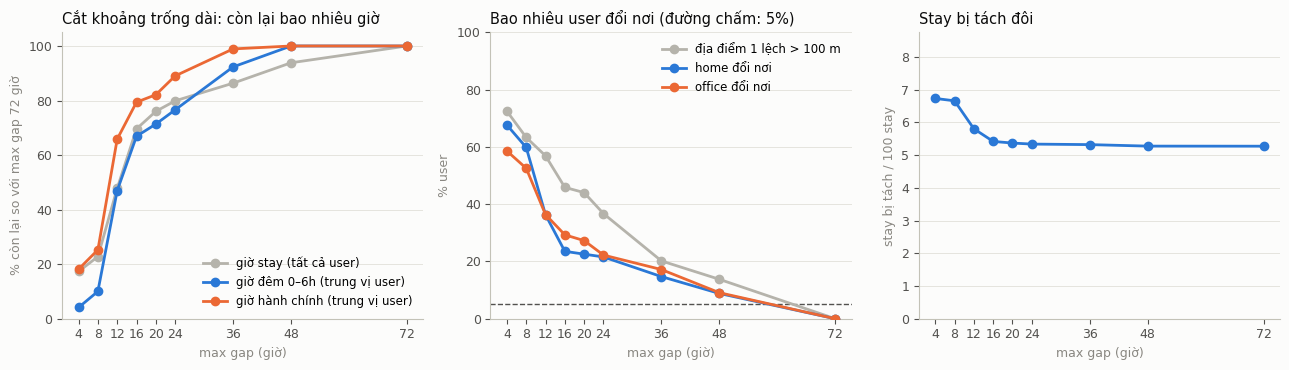

In [6]:
MG_USERS = None      # ví dụ ["000", "001", "002"] để chạy thử nhanh

mg_users = split.val_users()
if MG_USERS:
    mg_users = [u for u in mg_users if u in set(MG_USERS)]
M23, P23 = sa.run_maxgap(mg_users)
bang23 = sa.maxgap_summary(M23, P23)
print(f"Bảng 2. Cắt ở từng mức max gap, so với {sa.BASE_CAP_H} giờ ({M23['user'].nunique()} user)")
display(bang23.T.round(1))
sp.maxgap_plot(bang23);

### 2.3 Khoảng trống dài hơn 24 giờ so với home / office từ GPS

Mục này xét cả khoảng trống trên 24 giờ. Đáp án tham chiếu là **địa điểm nhiều giờ GPS thật nhất** trong 0–6h (home) và 9–17h thứ 2–6 (office), chỉ cho user đủ giờ GPS (`MIN_GPS_NIGHT_H`, `MIN_GPS_OFFICE_H` của `gap_evidence.py`, bảng user đã có cache từ notebook 13). Mọi khoảng trống 30 phút–72 giờ của các user đó được xét, kể cả 24–72 giờ.

Theo độ dài khoảng trống: % hai đầu gần nhau (≤ 200 m), % **cả hai đầu cách đáp án ≤ 300 m**, và % đó trong số khoảng trống có hai đầu gần nhau (loại sẽ bị nối thành stay).

**Hạn chế:** chỉ khoảng 20 user đủ giờ GPS đêm làm đáp án home và ít hơn cho office, nên cột `n user` và `n (hai đầu gần)` quyết định có kết luận được không. Đáp án lấy từ giờ máy bật nên có thể lệch với nơi ở lúc máy tắt. Hai đầu cùng ở home chưa chứng minh người đó ở yên suốt lúc tắt máy.

In [7]:
from eda import gap_evidence as ge, gap_long as gl
importlib.reload(ge); importlib.reload(gl)
U106, _, _ = ge.run_evidence(split.val_users())
GL = gl.run_long(U106)
print(f"{GL['user'].nunique()} user đủ giờ GPS làm đáp án, {len(GL)} khoảng trống 30 phút–72 giờ")
for what in ("home", "office"):
    n_u = int((U106[f"{what}_gps_hours"] >= (ge.MIN_GPS_NIGHT_H if what == "home" else ge.MIN_GPS_OFFICE_H)).sum())
    print(f"\nBảng 2.3 ({what}): {n_u} user đủ giờ GPS")
    display(gl.long_table(GL, what).round(1))

79 user đã có kết quả, 36 user cần tính, 15 tiến trình
[20/36] (3 giây)
[36/36] (6 giây)
14 user đủ giờ GPS làm đáp án, 8435 khoảng trống 30 phút–72 giờ

Bảng 2.3 (home): 12 user đủ giờ GPS


,n khoảng trống,n user,hai đầu gần nhau (%),cả hai đầu ở home (%),n (hai đầu gần),"ở home, trong số hai đầu gần (%)"
"(0.5, 1.0]",1059.0,12.0,68.1,11.7,721.0,16.5
"(1.0, 2.0]",781.0,12.0,68.1,11.8,532.0,16.5
"(2.0, 4.0]",657.0,12.0,51.0,7.2,335.0,11.3
"(4.0, 8.0]",390.0,12.0,34.4,6.9,134.0,16.4
"(8.0, 12.0]",1204.0,11.0,45.4,14.2,547.0,21.9
"(12.0, 24.0]",1520.0,12.0,35.6,24.7,541.0,42.5
"(24.0, 36.0]",157.0,11.0,24.8,12.7,39.0,28.2
"(36.0, 48.0]",136.0,12.0,31.6,22.8,43.0,53.5
"(48.0, 72.0]",83.0,11.0,24.1,13.3,20.0,35.0



Bảng 2.3 (office): 4 user đủ giờ GPS


,n khoảng trống,n user,hai đầu gần nhau (%),cả hai đầu ở office (%),n (hai đầu gần),"ở office, trong số hai đầu gần (%)"
"(0.5, 1.0]",778.0,4.0,80.1,15.4,623.0,18.3
"(1.0, 2.0]",537.0,4.0,70.4,17.1,378.0,22.2
"(2.0, 4.0]",432.0,4.0,52.3,12.5,226.0,21.2
"(4.0, 8.0]",254.0,4.0,38.2,11.4,97.0,20.6
"(8.0, 12.0]",762.0,4.0,29.0,11.9,221.0,23.5
"(12.0, 24.0]",660.0,4.0,25.2,4.1,166.0,10.8
"(24.0, 36.0]",89.0,4.0,21.3,6.7,19.0,21.1
"(36.0, 48.0]",56.0,4.0,25.0,1.8,14.0,7.1
"(48.0, 72.0]",31.0,3.0,12.9,0.0,4.0,0.0


**Đọc kết quả** (số ở bảng trên): nếu % hai đầu cùng ở home / office giảm rõ khi khoảng trống dài hơn 24 giờ, đó là bằng chứng nối qua 24 giờ kém tin hơn. Nếu vẫn ở mức như khoảng 12–24 giờ thì không có lý do cắt ở 24 giờ. Khoảng nào có `n user` hoặc `n (hai đầu gần)` nhỏ (dưới 30 khoảng trống hoặc dưới 5 user) thì **không kết luận**.

**Kết quả:** _chưa có. Chạy lại notebook trên nhóm validation của bản chia mới rồi ghi kết luận ở đây._


### 2.4 Mức nhạy quanh 24 giờ: so từng cặp max gap

Bảng 2.2 so mọi mức với 72 giờ. Ở đây so **từng cặp**: hàng là mức chuẩn, cột là mức so; ô là % user có địa điểm 1 / home / office dời xa hơn ngưỡng (100 m cho địa điểm 1, 200 m cho home và office) hoặc mất hẳn bằng chứng. Nếu 24 giờ so với 20 hoặc 36 giờ chỉ đổi ít user thì kết quả không phụ thuộc nhiều vào lựa chọn quanh 24 giờ.

In [8]:
pair = sa.maxgap_pairwise(M23, P23, caps=(12, 20, 24, 36, 48, 72))
for k, t in pair.items():
    print(f"Bảng 2.4. % user có {k} đổi nơi giữa hai mức max gap")
    display(t.round(1))

Bảng 2.4. % user có địa điểm 1 đổi nơi giữa hai mức max gap


so với (giờ),12,20,24,36,48,72
chuẩn (giờ),,,,,,
12,0.0,34.6,37.4,44.9,53.3,56.1
20,35.2,0.0,10.2,28.7,36.1,43.5
24,38.0,10.2,0.0,22.2,29.6,36.1
36,45.4,28.7,22.2,0.0,13.0,19.4
48,54.1,36.7,30.3,13.8,0.0,13.8
72,56.9,44.0,36.7,20.2,13.8,0.0


Bảng 2.4. % user có home đổi nơi giữa hai mức max gap


so với (giờ),12,20,24,36,48,72
chuẩn (giờ),,,,,,
12,0.0,14.8,17.0,17.0,23.9,26.1
20,20.2,0.0,3.2,4.3,10.6,16.0
24,23.2,4.2,0.0,4.2,10.5,15.8
36,25.5,8.2,7.1,0.0,5.1,11.2
48,32.3,15.2,14.1,6.1,0.0,6.1
72,36.3,22.5,21.6,14.7,8.8,0.0


Bảng 2.4. % user có office đổi nơi giữa hai mức max gap


so với (giờ),12,20,24,36,48,72
chuẩn (giờ),,,,,,
12,0.0,14.6,16.9,23.6,27.0,29.2
20,17.4,0.0,5.4,13.0,17.4,21.7
24,19.6,5.4,0.0,10.9,12.0,16.3
36,26.1,13.0,10.9,0.0,5.4,10.9
48,31.6,20.0,14.7,8.4,0.0,5.3
72,36.4,27.3,22.2,17.2,9.1,0.0


**Đọc kết quả** (số ở bảng trên): hàng 24 cho biết chuyển từ 24 giờ sang mỗi mức khác đổi bao nhiêu % user. Ô nhỏ (dưới khoảng 5%) nghĩa là hai mức gần như cho cùng kết quả; ô lớn nghĩa là việc chọn max gap ảnh hưởng trực tiếp đến home / office. Bảng chỉ đo độ nhạy, không đo đúng sai (A13).

**Kết quả:** _chưa có. Chạy lại notebook trên nhóm validation của bản chia mới rồi ghi kết luận ở đây._
